In [1]:
NAMES = ['Angela DiAndreth', 'Sergey Dutt', 'Edward Lombo-Becerra']

In [2]:
import jax
import jax.numpy as jnp
import numpy as np
import scipy.signal as signal
import matplotlib.pyplot as plt

In [3]:
from fix_data import get_random_subset, load_and_center_data  

In [4]:
df = load_and_center_data('Pendulum.xlsx')
subset_df = get_random_subset(df, 10)

t_start_orig = subset_df['Time'].iloc[0]
t_end_orig = subset_df['Time'].iloc[-1]

print(f"Subset original time window: {t_start_orig:.1f} s to {t_end_orig:.1f} s")

subset_df['Time'] = subset_df['Time'] - subset_df['Time'].iloc[0]

t_data = np.array(subset_df['Time'].values)
theta_data = np.array(subset_df['Angle'].values)

Subset original time window: 311.4 s to 337.6 s


In [5]:
def f_series(t_data, theta_data, K_max = 10, tol = 0.01):
    peaks, _ = signal.find_peaks(theta_data) # find peaks                                  

    t_diff = t_data[peaks[-1]] - t_data[peaks[0]]
    T_avg = t_diff / (len(peaks) - 1) # average period                                     

    freq = 2 * np.pi / T_avg

    first_peak = theta_data[peaks[0]]
    last_peak = theta_data[peaks[-1]]
    Lambda = np.log(first_peak / last_peak) / t_diff # decay constant                      
    decay = np.exp(-Lambda * t_data)

    for K in range(1, K_max + 1):
        cols = []
        for k in range(1, K + 1):
            cols.append(decay * np.cos(k * freq * t_data))
            cols.append(decay * np.sin(k * freq * t_data))

        # linear regression to determine A_k and B_k                                       
        X_k = np.column_stack(cols)
        Y_k = theta_data

        a_k = np.linalg.solve(X_k.T @ X_k, X_k.T @ Y_k)

        theta_model = X_k @ a_k

        MSE = np.mean((theta_data - theta_model)**2)

        if K > 1: # this step is skipped on first iteration                                
            rel_improvement = (prev_MSE - MSE) / prev_MSE
            if rel_improvement < tol:
                break

        a = a_k
        K_total = K
        prev_MSE = MSE
        
    return a, Lambda, freq, K_total

In [6]:
a, Lambda, freq, K_total = f_series(t_data, theta_data)
print(f'Number of cos/sin series in Fourier Series is k = {K_total}')

a = jnp.array(a)
def theta_func(t_m): # m data points (t_m, theta_m)                                        
    decay_t = jnp.exp(-Lambda * t_m)
    terms = jnp.array([
        a[2*(k-1)] * jnp.cos(k * freq * t_m) +
        a[2*(k-1)+1] * jnp.sin(k * freq * t_m)
        for k in range(1, K_total + 1)
    ])
    return decay_t * jnp.sum(terms)

Number of cos/sin series in Fourier Series is k = 2


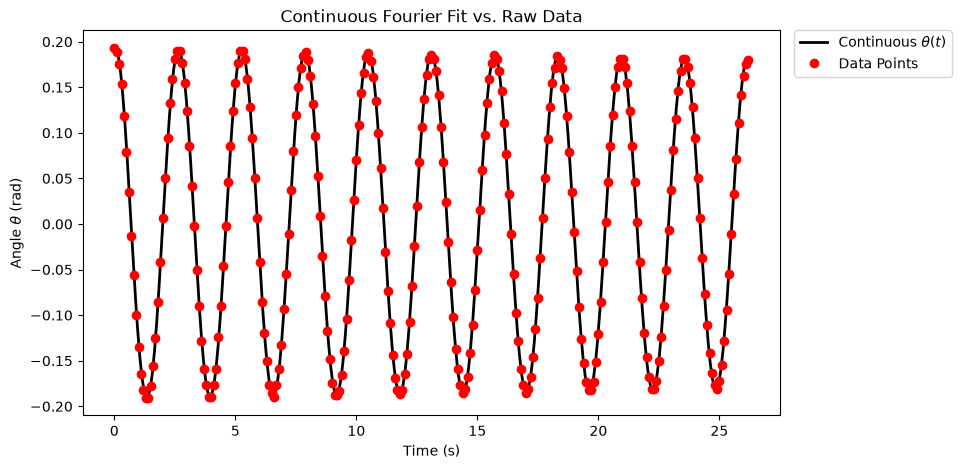

In [7]:
# plot Fourier Series Solution                                                             

t_plot = jnp.linspace(t_data[0], t_data[-1], 300)
theta_plot = jax.vmap(theta_func)(t_plot)

plt.figure(figsize=(9, 5), dpi=100)
plt.plot(t_plot, theta_plot, label='Continuous $\\theta(t)$', color='black', linewidth=2)
plt.plot(t_data, theta_data, 'ro', label='Data Points')
plt.xlabel('Time (s)')
plt.ylabel('Angle $\\theta$ (rad)')
plt.title('Continuous Fourier Fit vs. Raw Data')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
plt.show()

In [8]:
@jax.jit # for fast computation of jax.grad(jax.grad())                                    
def get_derivatives(t):

    dtheta_dt = jax.vmap(jax.grad(theta_func))(t)
    d2theta_dt2 = jax.vmap(jax.grad(jax.grad(theta_func)))(t)

    return dtheta_dt, d2theta_dt2

theta_dot, theta_ddot = get_derivatives(t_data)

In [9]:
# linear regression againts pendulum model: Xa = Y                                         
# physics model: x'' = -a1 * x' - a2 * sin(x), x = theta   
Y = theta_ddot
X = jnp.column_stack([-theta_dot, -jnp.sin(theta_data)])

a = jnp.linalg.solve(X.T @ X, X.T @ Y)
a1 = float(a[0])
a2 = float(a[1])

# a1 = c / m*L^2, a2 = g/L                                                                 
g = 9.81 # m / s^2                                                                         
L_data = 1.615 # m                                                                         
m_data = 1 # kg                                                                            

L_model = g / a2
L_err = jnp.abs(L_model - L_data) * 100
C_model = a1 * m_data * (L_model**2)

print(f'L_model: {L_model:.3f} m')
print(f'L_model error: {float(L_err):.3f} cm')
print(f'a1: {a1:.3f}')
print(f'Air-Resistance Coef (C): {C_model:.3f}')

L_model: 1.689 m
L_model error: 7.440 cm
a1: 0.005
Air-Resistance Coef (C): 0.013


In [10]:
from scipy.integrate import solve_ivp
from scipy.optimize import curve_fit

In [11]:
def pendulum_model(t, y, gamma, L = 1.615, g = 9.81):
    """
    Parameters:
    t: current time point
    y: state vector [theta, omega]
    - theta is angular displacement
    - omega is angular velocity
    gamma: damping parameter
    L: length of the pendulum (1.615)
    g: acceleration due to gravity (9.81)
    """
    theta, omega = y
    dtheta_dt = omega
    domega_dt = -gamma * omega - (g / L) * np.sin(theta)

    return [dtheta_dt, domega_dt]

In [12]:
def solve_pendulum_ivp(t_eval, *params):
    theta_0 = subset_df['Angle'].iloc[0]
    omega_0 = 0 # no initial velocity
    y0 = [theta_0, omega_0]

    sol = solve_ivp(
        fun = pendulum_model,
        t_span = (t_eval[0], t_eval[-1]),
        y0 = y0,
        t_eval = t_eval,
        args = params, # args must be a tuple
        method = 'RK45',
    )

    return sol.y[0] # return theta values

In [13]:
# Plotting function for reusable plotting of data and model fit
def plot_model(time_data, angle_data, model_fun, fit_params, description = ''):
    """
    Generates plot of with model line and data points
    Works with 1 or multiple free parameters
    """
    plt.close('all') # close any open figures
    t_model = np.linspace(time_data.iloc[0], time_data.iloc[-1], 500)

    if isinstance(fit_params, (list, tuple, np.ndarray)):
        params = tuple(fit_params)
    else:
        params = (fit_params,)

    y_model = model_fun(t_model, *params)

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(
        time_data,
        angle_data,
        'ko',
        markersize = 3,
        label = 'Data',
    )

    # plot modeled trajectory
    ax.plot(t_model, y_model, color = 'crimson', linewidth = 2, label = 'Model')

    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Angle (rad)')
    ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
    fig.suptitle(f'Pendulum Angle vs Time for {description}')
    plt.show()

Optimized Damping Coefficents -> gamma: 0.00520 ± 0.00026 s^-1
                              -> L:     1.69861 ± 0.0002 m


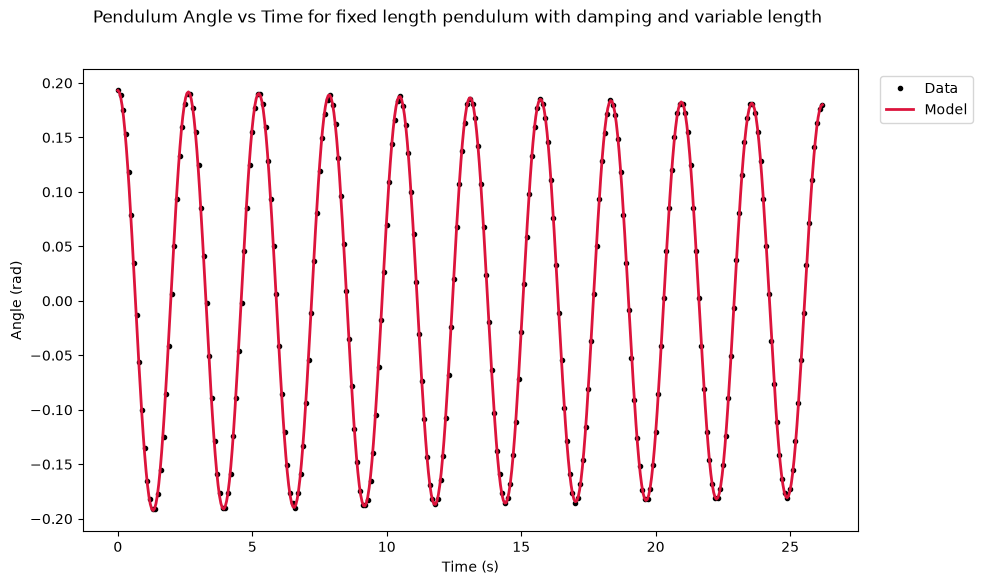

In [14]:
popt_2p, pcov_2p = curve_fit(
    solve_pendulum_ivp,
    subset_df['Time'].values,
    subset_df['Angle'].values,
    p0=[0.05, 1.615],  # initial guesses: gamma=0.05, L=1.615m
    bounds=([0.0, 1.0], [1.0, 2.0]),
)

gamma_fit, L_fit = popt_2p
gamma_err, L_err = np.sqrt(np.diag(pcov_2p))
print(f'Optimized Damping Coefficents -> gamma: {gamma_fit:.5f} ± {gamma_err:.5f} s^-1')
print(f'                              -> L:     {L_fit:.5f} ± {L_err:.4f} m')

plot_model(
    time_data = subset_df['Time'],
    angle_data = subset_df['Angle'],
    model_fun = solve_pendulum_ivp,
    fit_params = (gamma_fit, L_fit),
    description = 'fixed length pendulum with damping and variable length'
)